## Lab EDA Bivariate Analysis: Diving into Amazon UK Product insights Part II



In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline
pd.set_option('display.max_columns', None)

In [2]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

### Part 1: Analyzing Best-Seller Trends across Product Categories

In [3]:
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [4]:
crosstabresult = pd.crosstab(df['category'], ['isBestSeller'])
print(crosstabresult)

col_0                           isBestSeller
category                                    
3D Printers                              248
3D Printing & Scanning                  4067
Abrasive & Finishing Products            250
Action Cameras                          1697
Adapters                                 254
...                                      ...
Wind Instruments                         250
Window Treatments                        239
Women                                  17772
Women's Sports & Outdoor Shoes          1959
eBook Readers & Accessories              246

[296 rows x 1 columns]


In [5]:
proportionBS = df.groupby('category')['isBestSeller'].mean()*100
proportionBS = proportionBS.sort_values(ascending=False)
print(proportionBS)


category
Grocery                             5.813467
Smart Home Security & Lighting      5.769231
Health & Personal Care              5.768628
Mobile Phone Accessories            4.247104
Power & Hand Tools                  3.533895
                                      ...   
CD, Disc & Tape Players             0.000000
General Music-Making Accessories    0.000000
Snowboard Boots                     0.000000
Boxes & Organisers                  0.000000
eBook Readers & Accessories         0.000000
Name: isBestSeller, Length: 296, dtype: float64


### Crosstab analysis:

It seems that in the categories: Grocery, Smart Home Security& Lighting, Health & Personal Care, Mobile Phone Accessories and Power & Hand tools that it's more prevalent to be a best-seller. However the percentages are quite low, around 5%. Which means that 95% of the products are not bestsellers. 

### Statistical Tests

In [6]:
from scipy.stats import chi2_contingency

In [7]:
_, chi2_pvalue, _, _  = chi2_contingency(crosstabresult)
type(chi2_pvalue)

float

In [8]:
float(chi2_pvalue)

1.0

In [9]:
float(chi2_pvalue) < 0.05

False

The p value is not smaller than 0.05 (or alpha) we do not have a correlation between 2 categorical variables. This means that the best-seller distribution is independent of the product category. 

In [10]:
from scipy.stats.contingency import association

In [11]:
association(crosstabresult, method='cramer')

c:\Users\Asus\anaconda3\Lib\site-packages\scipy\stats\contingency.py:512: RuntimeWarning: invalid value encountered in scalar divide
  value = phi2 / min(n_cols - 1, n_rows - 1)


nan

In [12]:
proportionBS = proportionBS.sort_values(ascending=False)
proportionBS = proportionBS.head(20)
print(proportionBS)

category
Grocery                           5.813467
Smart Home Security & Lighting    5.769231
Health & Personal Care            5.768628
Mobile Phone Accessories          4.247104
Power & Hand Tools                3.533895
Billiard, Snooker & Pool          3.212851
Pet Supplies                      3.020028
Home Brewing & Wine Making        2.845528
Wind Instruments                  2.800000
Mirrors                           2.800000
Professional Medical Supplies     2.734375
PC & Video Games                  2.546634
Bakeware                          2.510460
Material Handling Products        2.500000
Bedding Accessories               2.439024
Tableware                         2.409639
Arts & Crafts                     2.408629
Baby                              2.265781
Lighting                          2.255639
Window Treatments                 2.092050
Name: isBestSeller, dtype: float64


(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
        17, 18, 19]),
 [Text(0, 0, 'Grocery'),
  Text(1, 0, 'Smart Home Security & Lighting'),
  Text(2, 0, 'Health & Personal Care'),
  Text(3, 0, 'Mobile Phone Accessories'),
  Text(4, 0, 'Power & Hand Tools'),
  Text(5, 0, 'Billiard, Snooker & Pool'),
  Text(6, 0, 'Pet Supplies'),
  Text(7, 0, 'Home Brewing & Wine Making'),
  Text(8, 0, 'Wind Instruments'),
  Text(9, 0, 'Mirrors'),
  Text(10, 0, 'Professional Medical Supplies'),
  Text(11, 0, 'PC & Video Games'),
  Text(12, 0, 'Bakeware'),
  Text(13, 0, 'Material Handling Products'),
  Text(14, 0, 'Bedding Accessories'),
  Text(15, 0, 'Tableware'),
  Text(16, 0, 'Arts & Crafts'),
  Text(17, 0, 'Baby'),
  Text(18, 0, 'Lighting'),
  Text(19, 0, 'Window Treatments')])

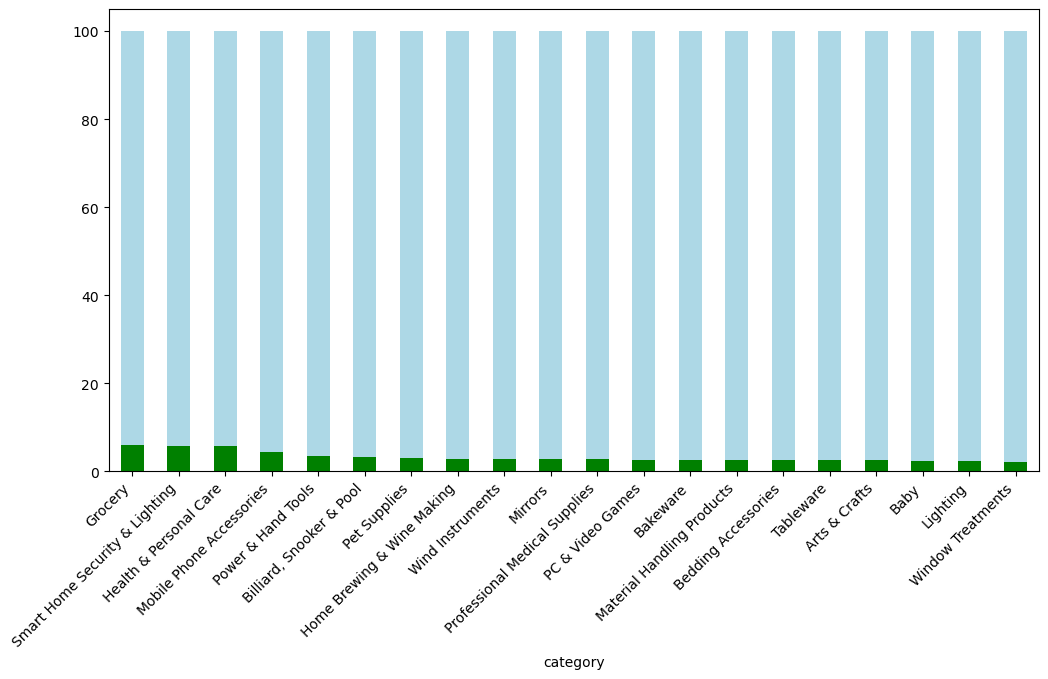

In [78]:
plot_df = pd.DataFrame({'BestSeller':proportionBS,
                       'NotBestSeller': 100 -  proportionBS
                       })

plot_df.plot(
    kind='bar',
    stacked=True,
    figsize=(12,6),
    color=['green', 'lightblue'],
    legend=False
    
)
plt.xticks(rotation=45, ha='right')

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

Objective: Investigate how different product categories influence product prices.

In [45]:
def outlier_price(df):
    Q1 = df['price'].quantile(0.25)
    Q3 = df['price'].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
  
    filtered = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)].copy()
    return(filtered)

df_clean = outlier_price(df)
print(df_clean)

             uid        asin  \
0              1  B09B96TG33   
1              2  B01HTH3C8S   
2              3  B09B8YWXDF   
3              4  B09B8T5VGV   
4              5  B09WX6QD65   
...          ...         ...   
2443646  2828589  B0CHSD7P2Q   
2443647  2828590  B0B7B8FNBQ   
2443648  2828591  B0BD5FL5FB   
2443649  2828592  B008OYLL4I   
2443650  2828593  B08P3W9B3T   

                                                     title  stars  reviews  \
0        Echo Dot (5th generation, 2022 release) | Big ...    4.7    15308   
1        Anker Soundcore mini, Super-Portable Bluetooth...    4.7    98099   
2        Echo Dot (5th generation, 2022 release) | Big ...    4.7    15308   
3        Echo Dot with clock (5th generation, 2022 rele...    4.7     7205   
4        Introducing Echo Pop | Full sound compact Wi-F...    4.6     1881   
...                                                    ...    ...      ...   
2443646  Motorbike Armour, Motorbike Clothing, Cycling ...    0.0    

In [51]:
BestSeller = df_clean.groupby('category')['isBestSeller'].mean()*100
BestSeller = BestSeller.sort_values(ascending=False)
top20 = BestSeller.head(20)
print(top20)
top20_categories = top20.index
df_top20 = df_clean[df_clean['category'].isin(top20_categories)]


category
Smart Home Security & Lighting         6.410256
Wind Instruments                       5.932203
Grocery                                5.813345
Health & Personal Care                 5.765199
Material Handling Products             4.819277
Professional Medical Supplies          4.545455
Billiard, Snooker & Pool               4.232804
Mobile Phone Accessories               3.937008
Home Brewing & Wine Making             3.846154
Motorbike Exhaust & Exhaust Systems    3.571429
Power & Hand Tools                     3.559100
Pet Supplies                           3.016463
PC & Video Games                       2.871190
Mirrors                                2.822581
String Instruments                     2.590674
Bakeware                               2.521008
Decking & Fencing                      2.469136
Bedding Accessories                    2.439024
Tableware                              2.419355
Arts & Crafts                          2.390438
Name: isBestSeller, dtype: floa

C:\Users\Asus\AppData\Local\Temp\ipykernel_16504\4279787794.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_top20, x="category", y="price", palette="coolwarm")


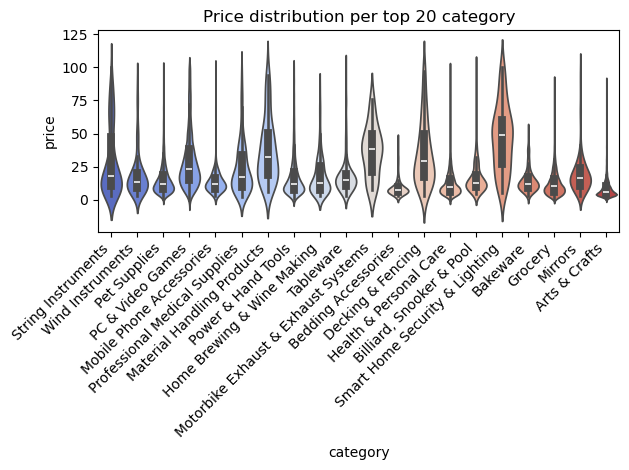

In [61]:
sns.violinplot(data=df_top20, x="category", y="price", palette="coolwarm")
plt.xticks(rotation=45, ha='right')
plt.title('Price distribution per top 20 category')
plt.tight_layout()
plt.show()

In [60]:
median_price = df_clean.groupby('category')['price'].median().sort_values(ascending=True)
top_value = median_price.max()
top_category = median_price.idxmax()
print(f'Category with the highest median price is **{top_category}** with a median of **{top_value}**')

Category with the highest median price is **Desktop PCs** with a median of **74.0**


## Bar Charts:

Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
Which product category commands the highest average price? Don't filter here by top categories

In [125]:
top10 = df_clean.category.value_counts().head(10).index
df_top10 = df_clean[df_clean.category.isin(top10)]


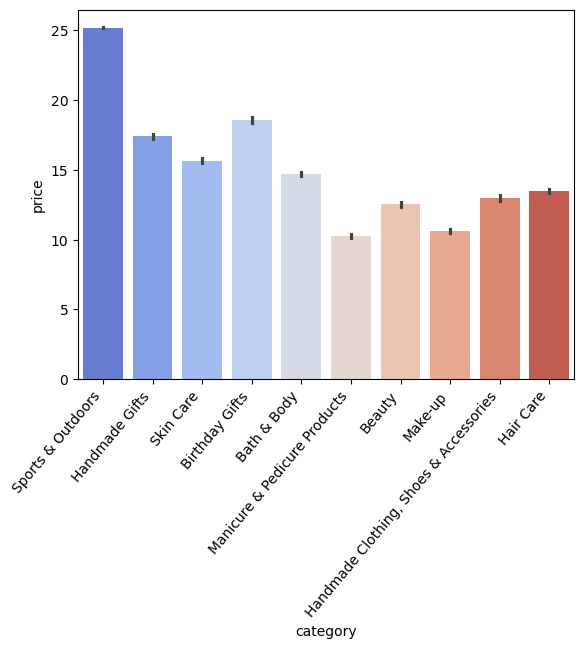

In [126]:
sns.barplot(
    data=df_top10, 
    x="category", 
    y="price", 
    hue='category',
    estimator='mean', 
    palette="coolwarm"
 )
plt.xticks(rotation=50, ha='right')
plt.show()

In [128]:
df_clean.groupby("category")["price"].mean().idxmax()

'Motherboards'

Product category 'Laptops' has the highest average price

### 3. Box plots:
Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
Which category tends to receive the highest median rating from customers? Don't filter here by top categories


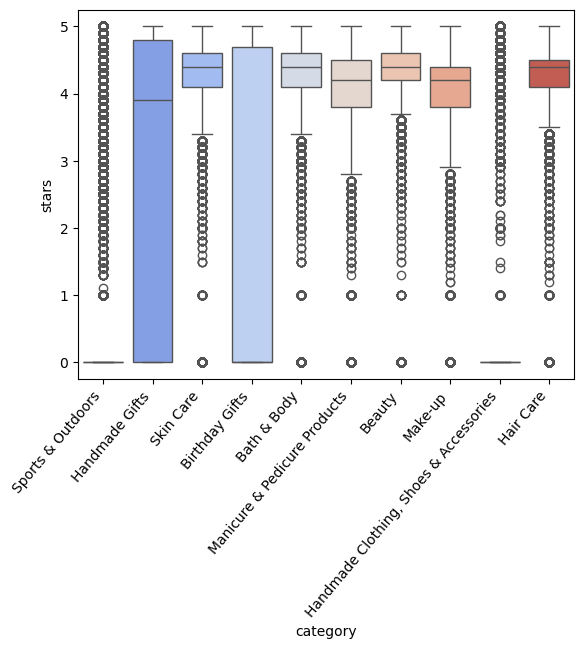

In [129]:
sns.boxplot(
    data=df_top10, 
    x="category", 
    y="stars", 
    hue='category',
    palette="coolwarm",
 )
plt.xticks(rotation=50, ha='right')
plt.show()

In [130]:
df_clean.groupby("category")["stars"].median().idxmax()

'Computer Memory'

The category 'Computer Memory' tends to receive the highest median rating. 

### Part 3: Investigating the Interplay Between Product Prices and Ratings
Objective: Analyze how product ratings (stars) correlate with product prices.



In [94]:
#Calculate the correlation coefficient between price and stars.
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association


In [134]:
crosstab_result2 = pd.crosstab(df_clean['price'], df_clean['stars'])
_, chi2_pvalue, _, _  = chi2_contingency(crosstab_result2)
a,b,c,d=chi2_contingency(crosstab_result2)

In [135]:
type(chi2_pvalue)

numpy.float64

In [136]:
float(chi2_pvalue)

0.0

In [137]:
float(chi2_pvalue) < 0.05

True

In [138]:
association(crosstab_result2, method='cramer')

0.087379252563221

The Chi-square test where the p-value < 0.05 implies that there's a statistically significant corelation between the 2 values. 

Cramérs V result of 0.08 can be interpretated as a **very weak**  assocation

### We can conclude that even thought there can be a association,  there's no significant correlation between product price and it's rating. 

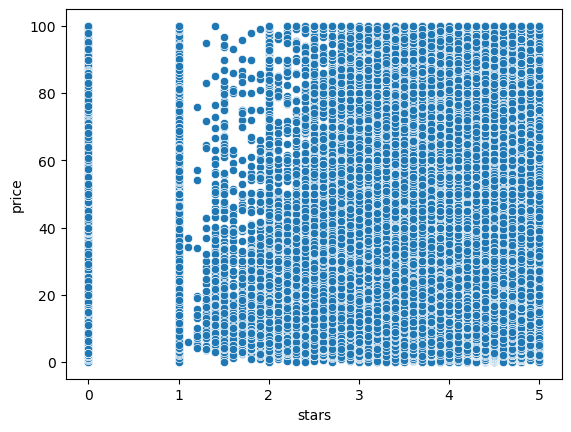

In [119]:
sns.scatterplot(data=df_clean, x='stars', y='price')
plt.show()

In [115]:
num = df_clean[['reviews','price','stars']]

In [116]:
num.corr()

,reviews,price,stars
reviews,1.000000,-0.008498,0.083920
price,-0.008498,1.000000,-0.077673
stars,0.083920,-0.077673,1.000000


In [117]:
num_matrix = num.corr()

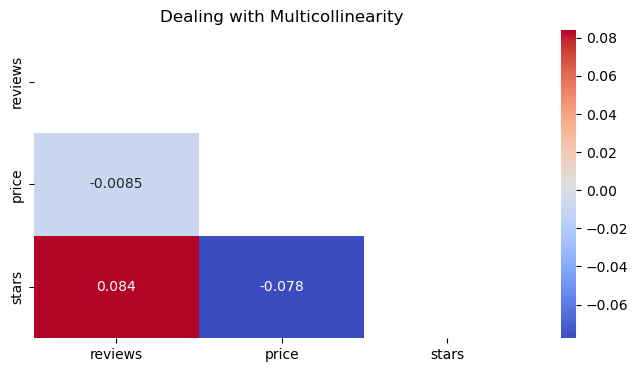

In [118]:
mask = np.triu(np.ones_like(num_matrix, dtype=bool))
plt.figure(figsize=(8, 4))
sns.heatmap(num_matrix, mask=mask, annot=True, cmap="coolwarm")

plt.title("Dealing with Multicollinearity")
plt.show()

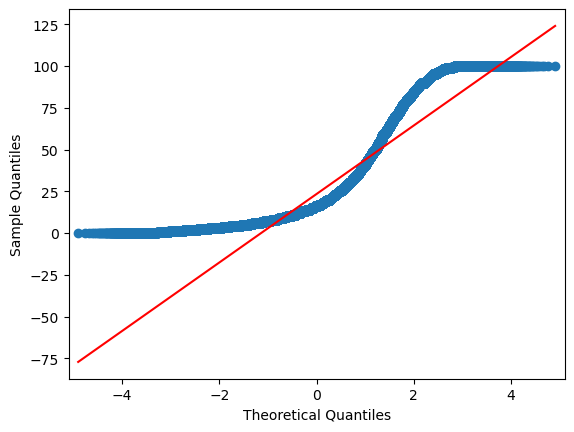

In [114]:
import statsmodels.api as sm

# Generating a Q-Q plot for 'price' to check if its distribution follows a normal distribution
sm.qqplot(df_clean['price'], line='s');
plt.show()

From the QQ plot of `price`:
- **Lower Tail**: In the lower tail (left side of the plot), the data points lie above the red line. This indicates that the distribution of `price` has heavier tails on the lower side than the normal distribution..
- **Upper Tail**: In the upper tail (right side of the plot), the data points deviate significantly from the red line, suggesting a short tail or a flatline to the right. This indicates that there are lower high values in `price` than would be expected in a normal distribution.
- **Central Portion**: The central portion of the data points doesn't align perfectly with the line, suggesting possible deviations from normality in the main body of the distribution as well.


**Conclusion:**

The `SalePrice` data is not normally distributed. It appears to be heavy clustered on the right side, with a hard limit of 100.  For statistical tests it's better to use Spearman. 

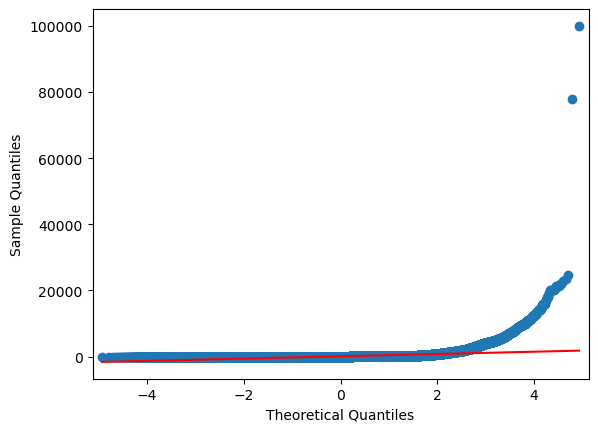

In [139]:
import statsmodels.api as sm

# Generating a Q-Q plot for 'price' to check if its distribution follows a normal distribution
sm.qqplot(df['price'], line='s');
plt.show()

In [ ]:
without taking out the outliers the lower and mid tail follow a quite normal distribution with a skewness to the right. Indicating that there are extreme high values on the higher end of the pricing. 